In [4]:
import os, glob, yaml, time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# ===== Paths =====
ROOT = "/kaggle/input/datasets/ketakichalke/ppe-kit-detection-construction-site-workers"
if not os.path.exists(ROOT):  # fallback: auto-detect the dataset folder
    hits = glob.glob("/kaggle/input/**/data/images", recursive=True)
    ROOT = os.path.dirname(os.path.dirname(hits[0])) if hits else ROOT

DATA = os.path.join(ROOT, "data")
SPLITS = ["train", "val", "test"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ===== Parallelism config =====
# File reading is I/O bound, so threads beyond CPU count still help
NUM_WORKERS = min(32, (os.cpu_count() or 2) * 4)

# ===== Sanity check =====
print("Dataset root :", ROOT)
print("Top-level    :", os.listdir(ROOT))
print("CPU cores    :", os.cpu_count())
print("Thread workers:", NUM_WORKERS)
print()
for kind in ["images", "labels"]:
    for s in SPLITS:
        p = os.path.join(DATA, kind, s)
        print(f"{kind:6s}/{s:5s} -> {'OK' if os.path.isdir(p) else 'MISSING'}")

Dataset root : /kaggle/input/datasets/ketakichalke/ppe-kit-detection-construction-site-workers
Top-level    : ['data']
CPU cores    : 4
Thread workers: 16

images/train -> OK
images/val   -> OK
images/test  -> OK
labels/train -> OK
labels/val   -> OK
labels/test  -> OK


In [5]:
def list_split(s):
    """List image and label files for one split."""
    img_dir = os.path.join(DATA, "images", s)
    lbl_dir = os.path.join(DATA, "labels", s)

    imgs, other_files = {}, []
    for e in os.scandir(img_dir):
        if not e.is_file():
            continue
        stem, ext = os.path.splitext(e.name)
        if ext.lower() in IMG_EXTS:
            imgs[stem] = e.name
        else:
            other_files.append(e.name)

    lbls = {os.path.splitext(e.name)[0] for e in os.scandir(lbl_dir)
            if e.is_file() and e.name.endswith(".txt")}
    return s, imgs, lbls, other_files


# ===== Run all splits in parallel =====
file_index = {}
t0 = time.time()
with ThreadPoolExecutor(max_workers=len(SPLITS)) as ex:
    futures = [ex.submit(list_split, s) for s in SPLITS]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Listing splits"):
        s, imgs, lbls, other = f.result()
        file_index[s] = {
            "imgs": imgs,                              # stem -> filename
            "lbls": lbls,                              # set of label stems
            "paired": sorted(set(imgs) & lbls),        # stems having both
            "no_label": sorted(set(imgs) - lbls),      # images without label
            "no_image": sorted(lbls - set(imgs)),      # orphan labels
            "other_files": other,                      # non-image files in images/
        }
print(f"Done in {time.time() - t0:.2f}s\n")

# ===== Pairing summary =====
pair_df = pd.DataFrame([{
    "split": s,
    "images": len(file_index[s]["imgs"]),
    "label_files": len(file_index[s]["lbls"]),
    "paired": len(file_index[s]["paired"]),
    "imgs_without_label": len(file_index[s]["no_label"]),
    "labels_without_img": len(file_index[s]["no_image"]),
    "non_image_files": len(file_index[s]["other_files"]),
} for s in SPLITS]).set_index("split")
pair_df.loc["TOTAL"] = pair_df.sum()
print("===== PAIRING SUMMARY =====")
print(pair_df, "\n")

# ===== Split ratio =====
total_imgs = pair_df.loc["TOTAL", "images"]
for s in SPLITS:
    print(f"{s:5s}: {pair_df.loc[s, 'images'] / total_imgs * 100:.1f}% of images")

# ===== Examples of problems (if any) =====
for s in SPLITS:
    for key in ["no_label", "no_image", "other_files"]:
        items = file_index[s][key]
        if items:
            print(f"\n[{s}] {key} (showing up to 5 of {len(items)}):", items[:5])

# ===== Data leakage check: same filename in multiple splits =====
print("\n===== LEAKAGE CHECK (same file name across splits) =====")
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = set(file_index[a]["imgs"]) & set(file_index[b]["imgs"])
    print(f"{a} & {b}: {len(overlap)} shared names", overlap and list(overlap)[:5] or "")

Listing splits:   0%|          | 0/3 [00:00<?, ?it/s]

Done in 0.28s

===== PAIRING SUMMARY =====
       images  label_files  paired  imgs_without_label  labels_without_img  \
split                                                                        
train    1132         1142    1132                   0                  10   
val       143          143     143                   0                   0   
test      141          141     141                   0                   0   
TOTAL    1416         1426    1416                   0                  10   

       non_image_files  
split                   
train                0  
val                  0  
test                 0  
TOTAL                0   

train: 79.9% of images
val  : 10.1% of images
test : 10.0% of images

[train] no_image (showing up to 5 of 10): ['image940(1)', 'image941(1)', 'image944(1)', 'image945(1)', 'image946(1)']

===== LEAKAGE CHECK (same file name across splits) =====
train & val: 0 shared names 
train & test: 0 shared names 
val & test: 0 shared names 


In [6]:
def parse_label(s, stem):
    """Parse one YOLO label file, return its boxes and any problems."""
    path = os.path.join(DATA, "labels", s, stem + ".txt")
    with open(path) as f:
        lines = [l.strip() for l in f if l.strip()]

    boxes, probs, seen = [], [], set()
    for i, line in enumerate(lines, 1):
        parts = line.split()
        if len(parts) != 5:
            probs.append(("bad_format", s, stem, i, line))
            continue
        try:
            cls = int(float(parts[0]))
            xc, yc, w, h = map(float, parts[1:])
        except ValueError:
            probs.append(("bad_format", s, stem, i, line))
            continue
        if not all(0 <= v <= 1 for v in (xc, yc, w, h)):
            probs.append(("out_of_range", s, stem, i, line))
        if w <= 0 or h <= 0:
            probs.append(("zero_size_box", s, stem, i, line))
        if line in seen:
            probs.append(("duplicate_box", s, stem, i, line))
        seen.add(line)
        boxes.append({"split": s, "stem": stem, "class_id": cls,
                      "xc": xc, "yc": yc, "w": w, "h": h})
    return s, stem, len(lines), boxes, probs


# ===== Build task list: only paired files =====
tasks = [(s, stem) for s in SPLITS for stem in file_index[s]["paired"]]

all_boxes, issues = [], defaultdict(list)
boxes_per_img = {s: {} for s in SPLITS}   # split -> {stem: n_boxes}

t0 = time.time()
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
    futures = [ex.submit(parse_label, s, stem) for s, stem in tasks]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Parsing labels"):
        s, stem, n, boxes, probs = f.result()
        boxes_per_img[s][stem] = n
        all_boxes.extend(boxes)
        for p in probs:
            issues[p[0]].append(p[1:])
print(f"Done in {time.time() - t0:.2f}s\n")

# ===== Master boxes DataFrame (reused in EDA) =====
boxes_df = pd.DataFrame(all_boxes)
print("===== BOXES DATAFRAME =====")
print("Shape:", boxes_df.shape)
print(boxes_df.head(), "\n")

# ===== Per split summary =====
print("===== BOXES PER SPLIT =====")
for s in SPLITS:
    counts = list(boxes_per_img[s].values())
    empty = sum(1 for c in counts if c == 0)
    print(f"{s:5s} | files {len(counts):5d} | boxes {sum(counts):6d} | empty files {empty}")

# ===== Label issues =====
print("\n===== LABEL ISSUES =====")
if not issues:
    print("No label issues found.")
for k, v in issues.items():
    print(f"{k}: {len(v)}")
    for ex_ in v[:5]:
        print("   ", ex_)

# ===== Orphan labels: are they copies of existing labels? =====
print("\n===== ORPHAN LABEL CHECK =====")
for s in SPLITS:
    for stem in file_index[s]["no_image"]:
        orphan = os.path.join(DATA, "labels", s, stem + ".txt")
        base = stem.replace("(1)", "").strip()
        original = os.path.join(DATA, "labels", s, base + ".txt")
        if os.path.exists(original):
            same = open(orphan).read().strip() == open(original).read().strip()
            print(f"[{s}] {stem}.txt vs {base}.txt -> {'IDENTICAL' if same else 'DIFFERENT'}")
        else:
            print(f"[{s}] {stem}.txt -> no original '{base}.txt' found")

Parsing labels:   0%|          | 0/1416 [00:00<?, ?it/s]

Done in 2.55s

===== BOXES DATAFRAME =====
Shape: (11521, 7)
   split       stem  class_id        xc        yc         w         h
0  train  image1164         1  0.617969  0.296539  0.067313  0.099359
1  train  image1164         1  0.462117  0.288961  0.084641  0.088953
2  train  image1164         3  0.575648  0.822508  0.164516  0.103672
3  train  image1164         6  0.578695  0.651781  0.301234  0.404938
4  train  image1164         6  0.379930  0.523383  0.377766  0.740734 

===== BOXES PER SPLIT =====
train | files  1132 | boxes   9098 | empty files 0
val   | files   143 | boxes   1172 | empty files 0
test  | files   141 | boxes   1251 | empty files 0

===== LABEL ISSUES =====
duplicate_box: 1
    ('train', 'image187', 6, '6 0.500117 0.517266 0.642766 0.965469')

===== ORPHAN LABEL CHECK =====
[train] image940(1).txt vs image940.txt -> IDENTICAL
[train] image941(1).txt vs image941.txt -> IDENTICAL
[train] image944(1).txt vs image944.txt -> IDENTICAL
[train] image945(1).txt vs image

In [7]:
import io, hashlib

def check_image(s, stem, fname):
    """Read one image: validity, size, format, mode, EXIF rotation, content hash."""
    path = os.path.join(DATA, "images", s, fname)
    rec = {"split": s, "stem": stem, "file": fname,
           "file_kb": os.path.getsize(path) / 1024}
    try:
        with open(path, "rb") as f:
            raw = f.read()
        rec["md5"] = hashlib.md5(raw).hexdigest()
        with Image.open(io.BytesIO(raw)) as im:
            rec["width"], rec["height"] = im.size
            rec["format"], rec["mode"] = im.format, im.mode
            try:
                rec["exif_orient"] = im.getexif().get(274, 1)  # 274 = Orientation tag
            except Exception:
                rec["exif_orient"] = 1
            im.verify()
        rec["ok"], rec["error"] = True, ""
    except Exception as e:
        rec["ok"], rec["error"] = False, str(e)
    return rec


# ===== Build task list =====
img_tasks = [(s, stem, fname) for s in SPLITS for stem, fname in file_index[s]["imgs"].items()]

img_records = []
t0 = time.time()
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
    futures = [ex.submit(check_image, *t) for t in img_tasks]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Checking images"):
        img_records.append(f.result())
print(f"Done in {time.time() - t0:.2f}s\n")

# ===== Master images DataFrame (reused in EDA) =====
img_df = pd.DataFrame(img_records)
img_df["aspect"] = (img_df["width"] / img_df["height"]).round(3)

# ===== Corrupt images =====
bad = img_df[~img_df["ok"]]
print("===== CORRUPT / UNREADABLE =====")
print(f"{len(bad)} found")
if len(bad):
    print(bad[["split", "file", "error"]].head(10))

ok_df = img_df[img_df["ok"]]

# ===== Formats and color modes =====
print("\n===== FORMATS =====")
print(ok_df["format"].value_counts())
print("\n===== COLOR MODES =====")
print(ok_df["mode"].value_counts())

# ===== Resolutions =====
print("\n===== TOP 10 RESOLUTIONS (w x h) =====")
print(ok_df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print("\nUnique resolutions:", ok_df.groupby(["width", "height"]).ngroups)
print(f"Width : min {ok_df['width'].min()} | max {ok_df['width'].max()} | median {ok_df['width'].median():.0f}")
print(f"Height: min {ok_df['height'].min()} | max {ok_df['height'].max()} | median {ok_df['height'].median():.0f}")
print(f"Aspect: min {ok_df['aspect'].min()} | max {ok_df['aspect'].max()} | median {ok_df['aspect'].median()}")

# ===== File sizes =====
print("\n===== FILE SIZE (KB) =====")
print(ok_df["file_kb"].describe().round(1))

# ===== EXIF rotation (can misalign boxes if not handled) =====
rot = ok_df[ok_df["exif_orient"] != 1]
print("\n===== EXIF ROTATED IMAGES =====")
print(f"{len(rot)} images have EXIF orientation != 1")
if len(rot):
    print(rot[["split", "file", "exif_orient"]].head(10))

# ===== Duplicate images by content =====
print("\n===== DUPLICATE IMAGES (same content) =====")
dup_groups = ok_df.groupby("md5").filter(lambda g: len(g) > 1).groupby("md5")
print(f"{dup_groups.ngroups} duplicate groups")
cross_split = 0
for _, g in list(dup_groups)[:10]:
    splits = set(g["split"])
    tag = "LEAKAGE" if len(splits) > 1 else "same split"
    cross_split += len(splits) > 1
    print(f"  [{tag}] {list(zip(g['split'], g['file']))}")
leak_total = sum(1 for _, g in dup_groups if g["split"].nunique() > 1)
print(f"\nDuplicate groups spanning multiple splits (leakage): {leak_total}")

Checking images:   0%|          | 0/1416 [00:00<?, ?it/s]

Done in 12.22s

===== CORRUPT / UNREADABLE =====
0 found

===== FORMATS =====
format
JPEG    1416
Name: count, dtype: int64

===== COLOR MODES =====
mode
RGB    1416
Name: count, dtype: int64

===== TOP 10 RESOLUTIONS (w x h) =====
width  height
640    640       1116
1024   768         41
       683         39
683    1024        26
768    1024        25
612    408         24
1024   1024        12
       681          9
       682          5
685    1024         5
dtype: int64

Unique resolutions: 93
Width : min 408 | max 1024 | median 640
Height: min 263 | max 1024 | median 640
Aspect: min 0.587 | max 2.327 | median 1.0

===== FILE SIZE (KB) =====
count    1416.0
mean      123.3
std       132.3
min        11.6
25%        46.5
50%        66.7
75%       155.5
max       901.5
Name: file_kb, dtype: float64

===== EXIF ROTATED IMAGES =====
0 images have EXIF orientation != 1

===== DUPLICATE IMAGES (same content) =====
0 duplicate groups

Duplicate groups spanning multiple splits (leakage): 0

===== CLASSES =====
Total classes: 11
split          name     group  train  val  test  total  pct_boxes  imgs_with_class  pct_imgs
class_id                                                                                    
0            helmet  positive   1341  201   192   1734      15.05             1047      73.9
1            gloves  positive   1146  136   163   1445      12.54              705      49.8
2              vest  positive   1269  171   178   1618      14.04             1048      74.0
3             boots  positive   1235  151   211   1597      13.86              669      47.2
4           goggles  positive    419   47    52    518       4.50              480      33.9
5              none     other    651   81    65    797       6.92              425      30.0
6            person  positive   1770  239   236   2245      19.49             1339      94.6
7         no_helmet  negative    400   45    40    485       4.21              283      20.0
8         no_goggle  negative   

Loading crops:   0%|          | 0/88 [00:00<?, ?it/s]

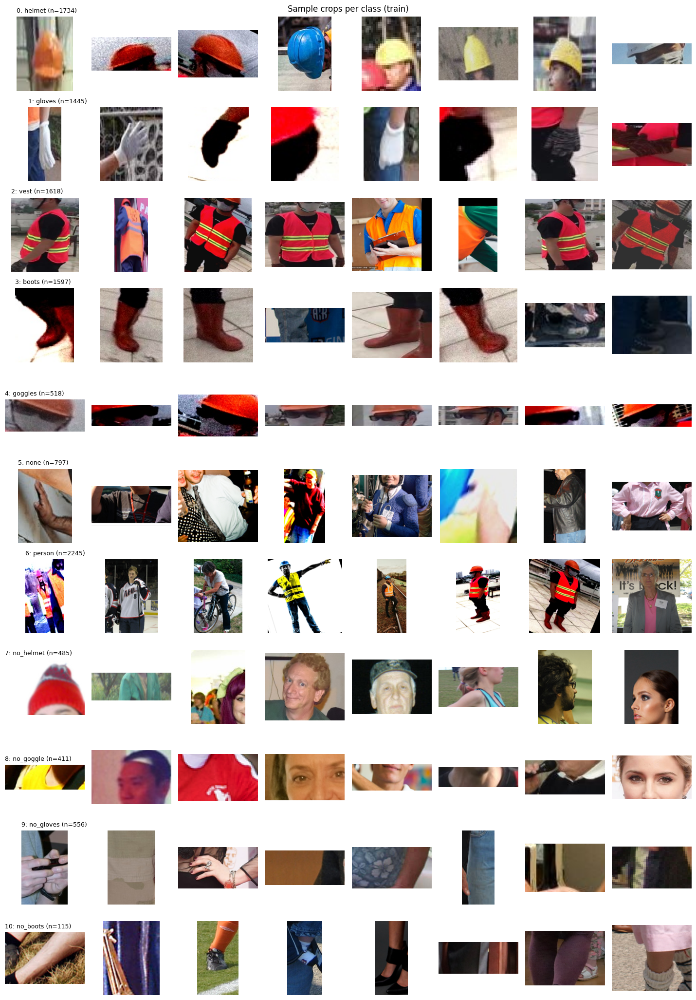

In [9]:
import random
import matplotlib.pyplot as plt

# ===== Class mapping (from Kaggle dataset description) =====
CLASS_NAMES = {
    0: "helmet", 1: "gloves", 2: "vest", 3: "boots", 4: "goggles",
    5: "none", 6: "person",
    7: "no_helmet", 8: "no_goggle", 9: "no_gloves", 10: "no_boots",
}
NAMES = [CLASS_NAMES[i] for i in range(len(CLASS_NAMES))]  # ordered list for data.yaml
CLASS_GROUP = {0: "positive", 1: "positive", 2: "positive", 3: "positive", 4: "positive",
               6: "positive", 5: "other",
               7: "negative", 8: "negative", 9: "negative", 10: "negative"}

boxes_df["class_name"] = boxes_df["class_id"].map(CLASS_NAMES)
boxes_df["group"] = boxes_df["class_id"].map(CLASS_GROUP)

# ===== Class table =====
all_ids = sorted(int(c) for c in boxes_df["class_id"].unique())
print("===== CLASSES =====")
print("Total classes:", len(all_ids))
assert set(all_ids) == set(CLASS_NAMES), "Mismatch between label IDs and mapping!"

cls_df = (boxes_df.pivot_table(index="class_id", columns="split", aggfunc="size", fill_value=0)
          .reindex(columns=SPLITS, fill_value=0))
cls_df.insert(0, "name", cls_df.index.map(CLASS_NAMES))
cls_df.insert(1, "group", cls_df.index.map(CLASS_GROUP))
cls_df["total"] = cls_df[SPLITS].sum(axis=1)
cls_df["pct_boxes"] = (cls_df["total"] / cls_df["total"].sum() * 100).round(2)
cls_df["imgs_with_class"] = (boxes_df.drop_duplicates(["split", "stem", "class_id"])
                             .groupby("class_id").size())
cls_df["pct_imgs"] = (cls_df["imgs_with_class"] / len(img_df) * 100).round(1)
print(cls_df.to_string())
print(f"\nImbalance ratio (max/min): {cls_df['total'].max() / cls_df['total'].min():.1f}x")

# ===== Group summary =====
print("\n===== GROUP SUMMARY =====")
grp = boxes_df.groupby("group").size()
print(pd.DataFrame({"boxes": grp, "pct": (grp / grp.sum() * 100).round(1)}))

# ===== Positive vs negative pairs =====
print("\n===== WEARING vs MISSING =====")
for pos, neg in [(0, 7), (4, 8), (1, 9), (3, 10)]:
    p, n = cls_df.loc[pos, "total"], cls_df.loc[neg, "total"]
    print(f"{CLASS_NAMES[pos]:8s} {p:5d} | {CLASS_NAMES[neg]:10s} {n:4d} | ratio {p / n:.1f} : 1")

# ===== Low-count warning for val/test =====
print("\n===== LOW COUNT CLASSES IN VAL/TEST (< 50) =====")
low = cls_df[(cls_df["val"] < 50) | (cls_df["test"] < 50)][["name", "val", "test"]]
print(low.to_string() if len(low) else "none")

# ===== Sample crops per class (parallel) =====
N_PER_CLASS = 8
PAD = 0.15
THUMB = 160

crop_tasks = []
for c in all_ids:
    g = boxes_df[(boxes_df["split"] == "train") & (boxes_df["class_id"] == c)]
    rows = g.sample(min(N_PER_CLASS, len(g)), random_state=42)
    for j, (_, r) in enumerate(rows.iterrows()):
        crop_tasks.append((c, j, r))

def load_crop(c, j, r):
    path = os.path.join(DATA, "images", r["split"], file_index[r["split"]]["imgs"][r["stem"]])
    with Image.open(path) as im:
        W, H = im.size
        bw, bh = r["w"] * W, r["h"] * H
        cx, cy = r["xc"] * W, r["yc"] * H
        x1 = max(0, cx - bw / 2 - bw * PAD)
        y1 = max(0, cy - bh / 2 - bh * PAD)
        x2 = min(W, cx + bw / 2 + bw * PAD)
        y2 = min(H, cy + bh / 2 + bh * PAD)
        crop = im.crop((int(x1), int(y1), int(x2), int(y2))).convert("RGB")
        crop.thumbnail((THUMB, THUMB))
        return c, j, crop.copy()

crops = {}
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
    futures = [ex.submit(load_crop, *t) for t in crop_tasks]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Loading crops"):
        c, j, crop = f.result()
        crops[(c, j)] = crop

# ===== Plot grid: one row per class =====
fig, axes = plt.subplots(len(all_ids), N_PER_CLASS,
                         figsize=(N_PER_CLASS * 1.8, len(all_ids) * 1.9))
for i, c in enumerate(all_ids):
    for j in range(N_PER_CLASS):
        ax = axes[i, j]
        ax.axis("off")
        if (c, j) in crops:
            ax.imshow(crops[(c, j)])
        if j == 0:
            ax.set_title(f"{c}: {CLASS_NAMES[c]} (n={cls_df.loc[c, 'total']})",
                         fontsize=9, loc="left")
plt.suptitle("Sample crops per class (train)", fontsize=12)
plt.tight_layout()
plt.show()

In [10]:
import shutil

# ===== Config =====
KEEP = {0: "helmet", 1: "gloves", 2: "vest", 6: "person"}   # old_id -> name
OLD_TO_NEW = {old: new for new, old in enumerate(KEEP)}       # {0:0, 1:1, 2:2, 6:3}
NEW_NAMES = list(KEEP.values())                               # ['helmet','gloves','vest','person']
OUT = "/kaggle/working/ppe_4cls"
DROP_BACKGROUND = False   # True = skip images that end up with zero boxes

print("Old -> New mapping:", {f"{o}:{CLASS_NAMES[o]}": n for o, n in OLD_TO_NEW.items()})

# ===== Fresh output folders =====
if os.path.exists(OUT):
    shutil.rmtree(OUT)
for kind in ["images", "labels"]:
    for s in SPLITS:
        os.makedirs(os.path.join(OUT, kind, s), exist_ok=True)


def process(s, stem):
    """Filter + remap one label file, copy its image, write the new label."""
    src_lbl = os.path.join(DATA, "labels", s, stem + ".txt")
    kept, seen, removed, dups = [], set(), 0, 0
    with open(src_lbl) as f:
        for line in f:
            parts = line.split()
            if len(parts) != 5:
                continue
            old = int(float(parts[0]))
            if old not in OLD_TO_NEW:
                removed += 1
                continue
            new_line = f"{OLD_TO_NEW[old]} " + " ".join(parts[1:])
            if new_line in seen:
                dups += 1
                continue
            seen.add(new_line)
            kept.append(new_line)

    is_bg = len(kept) == 0
    if is_bg and DROP_BACKGROUND:
        return s, len(kept), removed, dups, is_bg, False

    fname = file_index[s]["imgs"][stem]
    shutil.copy2(os.path.join(DATA, "images", s, fname),
                 os.path.join(OUT, "images", s, fname))
    with open(os.path.join(OUT, "labels", s, stem + ".txt"), "w") as f:
        f.write("\n".join(kept) + ("\n" if kept else ""))
    return s, len(kept), removed, dups, is_bg, True


# ===== Run in parallel =====
tasks = [(s, stem) for s in SPLITS for stem in file_index[s]["paired"]]
stats = {s: Counter() for s in SPLITS}

t0 = time.time()
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
    futures = [ex.submit(process, s, stem) for s, stem in tasks]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Filtering + copying"):
        s, k, r, d, bg, written = f.result()
        stats[s]["images_written"] += written
        stats[s]["background_imgs"] += bg
        stats[s]["boxes_kept"] += k
        stats[s]["boxes_removed"] += r
        stats[s]["duplicates_removed"] += d
print(f"Done in {time.time() - t0:.2f}s\n")

stats_df = pd.DataFrame(stats).T.reindex(SPLITS).fillna(0).astype(int)
stats_df.loc["TOTAL"] = stats_df.sum()
stats_df["bg_pct"] = (stats_df["background_imgs"] / stats_df["images_written"] * 100).round(2)
print("===== FILTER SUMMARY =====")
print(stats_df.to_string())

# ===== Write data.yaml =====
data_yaml = {
    "path": OUT,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(NEW_NAMES),
    "names": {i: n for i, n in enumerate(NEW_NAMES)},
}
YAML_PATH = os.path.join(OUT, "data.yaml")
with open(YAML_PATH, "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)
print(f"\n===== {YAML_PATH} =====")
print(open(YAML_PATH).read())

# ===== Verify output files =====
print("===== OUTPUT FILE COUNTS =====")
for s in SPLITS:
    n_img = len(os.listdir(os.path.join(OUT, "images", s)))
    n_lbl = len(os.listdir(os.path.join(OUT, "labels", s)))
    print(f"{s:5s} | images {n_img:5d} | labels {n_lbl:5d} | {'OK' if n_img == n_lbl else 'MISMATCH'}")

# ===== New boxes DataFrame for EDA =====
boxes4_df = (boxes_df[boxes_df["class_id"].isin(KEEP)]
             .drop_duplicates(["split", "stem", "class_id", "xc", "yc", "w", "h"])
             .copy())
boxes4_df["class_id"] = boxes4_df["class_id"].map(OLD_TO_NEW)
boxes4_df["class_name"] = boxes4_df["class_id"].map(dict(enumerate(NEW_NAMES)))

cls4_df = (boxes4_df.pivot_table(index="class_id", columns="split", aggfunc="size", fill_value=0)
           .reindex(columns=SPLITS, fill_value=0))
cls4_df.insert(0, "name", cls4_df.index.map(dict(enumerate(NEW_NAMES))))
cls4_df["total"] = cls4_df[SPLITS].sum(axis=1)
cls4_df["pct_boxes"] = (cls4_df["total"] / cls4_df["total"].sum() * 100).round(2)
print("\n===== NEW CLASS DISTRIBUTION (4 classes) =====")
print(cls4_df.to_string())
print(f"\nImbalance ratio (max/min): {cls4_df['total'].max() / cls4_df['total'].min():.1f}x")

Old -> New mapping: {'0:helmet': 0, '1:gloves': 1, '2:vest': 2, '6:person': 3}


Filtering + copying:   0%|          | 0/1416 [00:00<?, ?it/s]

Done in 1.57s

===== FILTER SUMMARY =====
       images_written  background_imgs  boxes_kept  boxes_removed  duplicates_removed  bg_pct
train            1132                5        5525           3572                   1    0.44
val               143                0         747            425                   0    0.00
test              141                0         769            482                   0    0.00
TOTAL            1416                5        7041           4479                   1    0.35

===== /kaggle/working/ppe_4cls/data.yaml =====
path: /kaggle/working/ppe_4cls
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: helmet
  1: gloves
  2: vest
  3: person

===== OUTPUT FILE COUNTS =====
train | images  1132 | labels  1132 | OK
val   | images   143 | labels   143 | OK
test  | images   141 | labels   141 | OK

===== NEW CLASS DISTRIBUTION (4 classes) =====
split       name  train  val  test  total  pct_boxes
class_id                                

/tmp/ipykernel_48/2580939967.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=melt, x="class", y="count", ax=ax, palette=COLORS, order=NEW_NAMES)


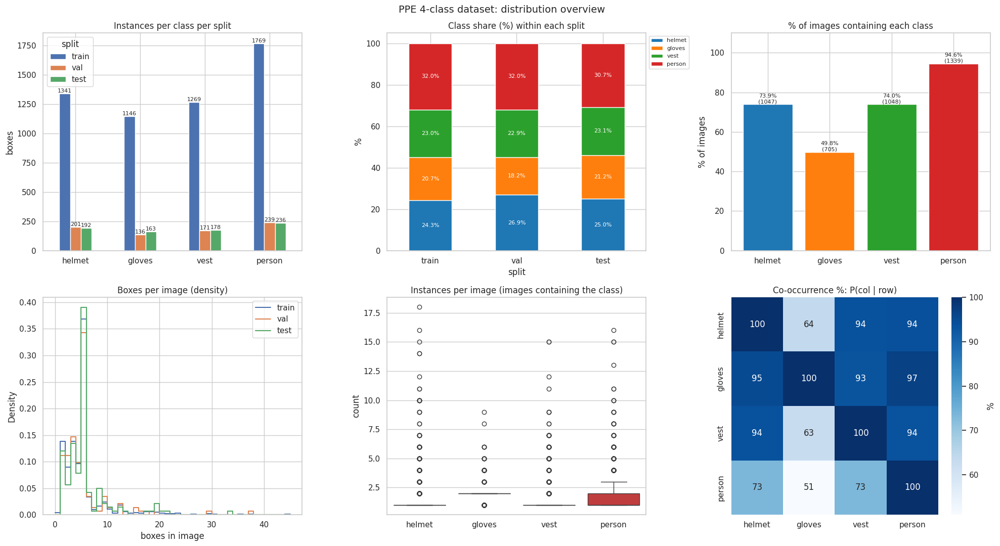

===== BOXES PER IMAGE =====
        count  mean   std  min  25%  50%  75%   max
split                                              
train  1132.0  4.88  4.18  0.0  3.0  5.0  5.0  44.0
val     143.0  5.22  4.89  1.0  3.0  5.0  5.0  37.0
test    141.0  5.45  4.58  1.0  3.0  5.0  5.0  33.0

Images with >= 15 boxes: 61
Max boxes in one image : 44

===== INSTANCES PER IMAGE BY CLASS (when present) =====
         count  mean   std  min  25%  50%  75%   max
class                                               
helmet  1047.0  1.66  1.78  1.0  1.0  1.0  1.0  18.0
gloves   705.0  2.05  0.75  1.0  2.0  2.0  2.0   9.0
vest    1048.0  1.54  1.45  1.0  1.0  1.0  1.0  15.0
person  1339.0  1.68  1.56  1.0  1.0  1.0  2.0  16.0


In [11]:
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
COLORS = dict(zip(NEW_NAMES, sns.color_palette("tab10", len(NEW_NAMES))))

# ===== Per-image tables =====
all_imgs = pd.DataFrame([(s, stem) for s in SPLITS for stem in file_index[s]["paired"]],
                        columns=["split", "stem"])
per_img = (all_imgs.merge(boxes4_df.groupby(["split", "stem"]).size()
                          .rename("n_boxes").reset_index(),
                          on=["split", "stem"], how="left")
           .fillna({"n_boxes": 0}))
per_img_cls = (boxes4_df.pivot_table(index=["split", "stem"], columns="class_name",
                                     aggfunc="size", fill_value=0)
               .reindex(columns=NEW_NAMES, fill_value=0))

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# ----- 1. Instances per class per split -----
ax = axes[0, 0]
counts = cls4_df.set_index("name")[SPLITS]
counts.plot(kind="bar", ax=ax, rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8)
ax.set_title("Instances per class per split")
ax.set_xlabel(""); ax.set_ylabel("boxes")

# ----- 2. Class share within each split (consistency check) -----
ax = axes[0, 1]
share = counts / counts.sum() * 100
share.T.plot(kind="bar", stacked=True, ax=ax, rot=0,
             color=[COLORS[n] for n in share.index])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f%%", label_type="center", fontsize=8, color="white")
ax.set_title("Class share (%) within each split")
ax.set_ylabel("%"); ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)

# ----- 3. Images containing each class -----
ax = axes[0, 2]
img_presence = (per_img_cls > 0).sum().reindex(NEW_NAMES)
pct = img_presence / len(all_imgs) * 100
bars = ax.bar(NEW_NAMES, pct, color=[COLORS[n] for n in NEW_NAMES])
ax.bar_label(bars, labels=[f"{p:.1f}%\n({c})" for p, c in zip(pct, img_presence)], fontsize=8)
ax.set_title("% of images containing each class")
ax.set_ylim(0, 110); ax.set_ylabel("% of images")

# ----- 4. Boxes per image histogram -----
ax = axes[1, 0]
for s in SPLITS:
    sns.histplot(per_img.loc[per_img["split"] == s, "n_boxes"], ax=ax, label=s,
                 stat="density", bins=range(0, int(per_img["n_boxes"].max()) + 2),
                 element="step", fill=False)
ax.set_title("Boxes per image (density)")
ax.set_xlabel("boxes in image"); ax.legend()

# ----- 5. Instances per image for each class (only images that contain it) -----
ax = axes[1, 1]
melt = per_img_cls.reset_index().melt(id_vars=["split", "stem"], value_vars=NEW_NAMES,
                                      var_name="class", value_name="count")
melt = melt[melt["count"] > 0]
sns.boxplot(data=melt, x="class", y="count", ax=ax, palette=COLORS, order=NEW_NAMES)
ax.set_title("Instances per image (images containing the class)")
ax.set_xlabel("")

# ----- 6. Co-occurrence: P(column present | row present) -----
ax = axes[1, 2]
presence = (per_img_cls > 0).astype(int)
co = presence.T @ presence
cond = co.div(np.diag(co), axis=0) * 100
sns.heatmap(cond, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "%"})
ax.set_title("Co-occurrence %: P(col | row)")
ax.set_xlabel(""); ax.set_ylabel("")

plt.suptitle("PPE 4-class dataset: distribution overview", fontsize=14)
plt.tight_layout()
plt.show()

# ===== Text summary =====
print("===== BOXES PER IMAGE =====")
print(per_img.groupby("split")["n_boxes"].describe().reindex(SPLITS).round(2))
print("\nImages with >= 15 boxes:", int((per_img["n_boxes"] >= 15).sum()))
print("Max boxes in one image :", int(per_img["n_boxes"].max()))

print("\n===== INSTANCES PER IMAGE BY CLASS (when present) =====")
print(melt.groupby("class")["count"].describe().reindex(NEW_NAMES).round(2))

/tmp/ipykernel_48/3211069431.py:22: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  samp = geo.groupby("class_name", group_keys=False).apply(
/tmp/ipykernel_48/3211069431.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=geo, x="class_name", y="aspect", order=NEW_NAMES, palette=COLORS,
/tmp/ipykernel_48/3211069431.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=geo, x="class_name", y="rel_

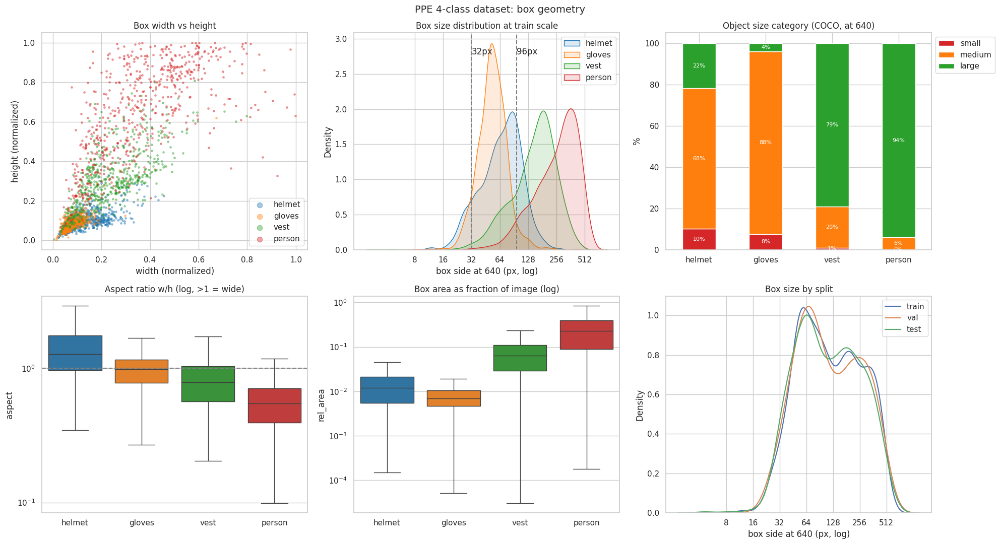

===== BOX SIDE AT 640 (px) PER CLASS =====
             count   mean    std  min    5%    25%    50%    75%    95%    max
class_name                                                                    
helmet      1734.0   73.4   35.3  7.8  26.3   47.3   69.5   93.6  133.8  282.3
gloves      1445.0   56.7   24.3  4.6  29.4   43.2   52.6   65.8   91.2  413.8
vest        1618.0  166.5   79.8  3.5  52.9  107.7  160.8  212.0  314.4  462.1
person      2244.0  286.8  127.5  8.5  93.0  181.5  288.2  382.9  496.7  631.9

===== SIZE CATEGORY % PER CLASS =====
size_cat    small  medium  large
class_name                      
helmet       10.3    67.9   21.9
gloves        7.6    88.4    4.0
vest          1.0    20.0   79.0
person        0.2     5.8   94.0

Overall: {'large': 54.3, 'medium': 41.3, 'small': 4.4}

===== ASPECT RATIO (w/h) MEDIAN PER CLASS =====
class_name
helmet    1.29
gloves    0.99
vest      0.79
person    0.55
Name: aspect, dtype: float64

===== TINY BOXES (< 8px side at 640): 3 

In [12]:
IMGSZ = 640

# ===== Attach image size to every box =====
geo = boxes4_df.merge(img_df[["split", "stem", "width", "height"]],
                      on=["split", "stem"], how="left")
geo["w_px"] = geo["w"] * geo["width"]
geo["h_px"] = geo["h"] * geo["height"]
geo["scale"] = IMGSZ / geo[["width", "height"]].max(axis=1)       # letterbox scale
geo["w640"] = geo["w_px"] * geo["scale"]
geo["h640"] = geo["h_px"] * geo["scale"]
geo["side640"] = np.sqrt(geo["w640"] * geo["h640"])                # equivalent square side
geo["rel_area"] = geo["w"] * geo["h"]                              # fraction of image
geo["aspect"] = geo["w_px"] / geo["h_px"]                          # >1 wide, <1 tall
geo["size_cat"] = pd.cut(geo["w640"] * geo["h640"],
                         bins=[0, 32**2, 96**2, np.inf],
                         labels=["small", "medium", "large"])

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# ----- 1. Width vs height (normalized) -----
ax = axes[0, 0]
samp = geo.groupby("class_name", group_keys=False).apply(
    lambda g: g.sample(min(600, len(g)), random_state=42))
for n in NEW_NAMES:
    d = samp[samp["class_name"] == n]
    ax.scatter(d["w"], d["h"], s=6, alpha=0.4, label=n, color=COLORS[n])
ax.set_xlabel("width (normalized)"); ax.set_ylabel("height (normalized)")
ax.set_title("Box width vs height"); ax.legend(markerscale=3)

# ----- 2. Box size at 640 (sqrt area) -----
ax = axes[0, 1]
for n in NEW_NAMES:
    sns.kdeplot(np.log10(geo.loc[geo["class_name"] == n, "side640"]),
                ax=ax, label=n, color=COLORS[n], fill=True, alpha=0.15)
for v, lbl in [(32, "32px"), (96, "96px")]:
    ax.axvline(np.log10(v), ls="--", c="gray"); ax.text(np.log10(v), ax.get_ylim()[1] * 0.9, lbl)
ticks = [8, 16, 32, 64, 128, 256, 512]
ax.set_xticks(np.log10(ticks)); ax.set_xticklabels(ticks)
ax.set_xlabel("box side at 640 (px, log)"); ax.set_title("Box size distribution at train scale")
ax.legend()

# ----- 3. Small / medium / large share per class -----
ax = axes[0, 2]
size_tab = pd.crosstab(geo["class_name"], geo["size_cat"], normalize="index").reindex(NEW_NAMES) * 100
size_tab.plot(kind="bar", stacked=True, ax=ax, rot=0, color=["#d62728", "#ff7f0e", "#2ca02c"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f%%", label_type="center", fontsize=8, color="white")
ax.set_title("Object size category (COCO, at 640)"); ax.set_ylabel("%"); ax.set_xlabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

# ----- 4. Aspect ratio per class -----
ax = axes[1, 0]
sns.boxplot(data=geo, x="class_name", y="aspect", order=NEW_NAMES, palette=COLORS,
            ax=ax, showfliers=False)
ax.axhline(1, ls="--", c="gray"); ax.set_yscale("log")
ax.set_title("Aspect ratio w/h (log, >1 = wide)"); ax.set_xlabel("")

# ----- 5. Relative area per class -----
ax = axes[1, 1]
sns.boxplot(data=geo, x="class_name", y="rel_area", order=NEW_NAMES, palette=COLORS,
            ax=ax, showfliers=False)
ax.set_yscale("log"); ax.set_title("Box area as fraction of image (log)"); ax.set_xlabel("")

# ----- 6. Size consistency across splits -----
ax = axes[1, 2]
for s in SPLITS:
    sns.kdeplot(np.log10(geo.loc[geo["split"] == s, "side640"]), ax=ax, label=s)
ax.set_xticks(np.log10(ticks)); ax.set_xticklabels(ticks)
ax.set_xlabel("box side at 640 (px, log)"); ax.set_title("Box size by split"); ax.legend()

plt.suptitle("PPE 4-class dataset: box geometry", fontsize=14)
plt.tight_layout()
plt.show()

# ===== Text summary =====
print("===== BOX SIDE AT 640 (px) PER CLASS =====")
print(geo.groupby("class_name")["side640"].describe(percentiles=[.05, .25, .5, .75, .95])
      .reindex(NEW_NAMES).round(1))

print("\n===== SIZE CATEGORY % PER CLASS =====")
print(size_tab.round(1))
print("\nOverall:", (geo["size_cat"].value_counts(normalize=True) * 100).round(1).to_dict())

print("\n===== ASPECT RATIO (w/h) MEDIAN PER CLASS =====")
print(geo.groupby("class_name")["aspect"].median().reindex(NEW_NAMES).round(2))

tiny = geo[geo["side640"] < 8]
print(f"\n===== TINY BOXES (< 8px side at 640): {len(tiny)} =====")
if len(tiny):
    print(tiny.groupby("class_name").size().reindex(NEW_NAMES, fill_value=0))
    print(tiny[["split", "stem", "class_name", "w640", "h640"]].head(10).round(1))

Coverage map:   0%|          | 0/7041 [00:00<?, ?it/s]

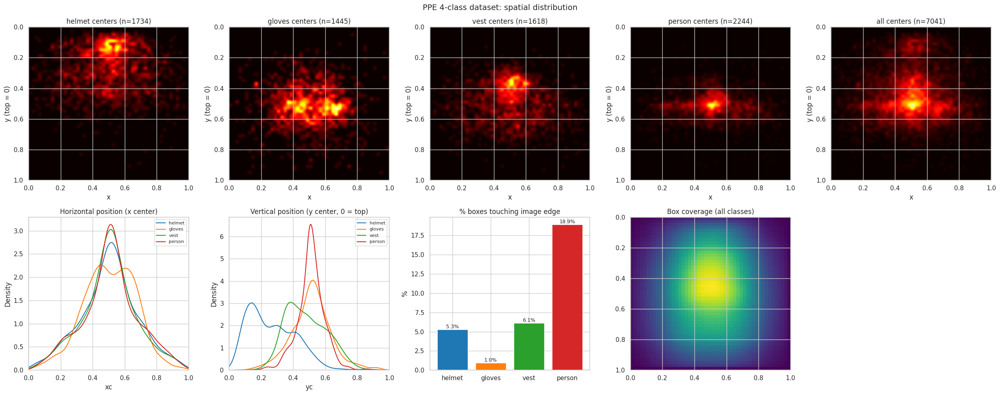

===== MEAN CENTER POSITION PER CLASS =====
               xc            yc       
             mean    std   mean    std
class_name                            
helmet      0.505  0.179  0.267  0.147
gloves      0.507  0.161  0.514  0.126
vest        0.504  0.171  0.482  0.129
person      0.511  0.175  0.511  0.086

===== BOXES TOUCHING IMAGE EDGE =====
            count   pct
class_name             
helmet         92   5.3
gloves         14   1.0
vest           99   6.1
person        425  18.9

Overall: 8.9% of boxes touch an edge


In [13]:
BINS = 50

# ===== Box edges (normalized) =====
geo["x1"] = geo["xc"] - geo["w"] / 2
geo["y1"] = geo["yc"] - geo["h"] / 2
geo["x2"] = geo["xc"] + geo["w"] / 2
geo["y2"] = geo["yc"] + geo["h"] / 2
EDGE = 0.005
geo["touch_edge"] = ((geo["x1"] <= EDGE) | (geo["y1"] <= EDGE) |
                     (geo["x2"] >= 1 - EDGE) | (geo["y2"] >= 1 - EDGE))

fig = plt.figure(figsize=(25, 10))

# ----- Row 1: center heatmaps per class + all -----
for i, n in enumerate(NEW_NAMES + ["all"]):
    ax = fig.add_subplot(2, 5, i + 1)
    d = geo if n == "all" else geo[geo["class_name"] == n]
    h, _, _ = np.histogram2d(d["yc"], d["xc"], bins=BINS, range=[[0, 1], [0, 1]])
    ax.imshow(h, cmap="hot", extent=[0, 1, 1, 0], interpolation="gaussian", aspect="auto")
    ax.set_title(f"{n} centers (n={len(d)})")
    ax.set_xlabel("x"); ax.set_ylabel("y (top = 0)")

# ----- Row 2a: x-center distribution -----
ax = fig.add_subplot(2, 5, 6)
for n in NEW_NAMES:
    sns.kdeplot(geo.loc[geo["class_name"] == n, "xc"], ax=ax, label=n, color=COLORS[n])
ax.set_xlim(0, 1); ax.set_title("Horizontal position (x center)"); ax.legend(fontsize=8)

# ----- Row 2b: y-center distribution -----
ax = fig.add_subplot(2, 5, 7)
for n in NEW_NAMES:
    sns.kdeplot(geo.loc[geo["class_name"] == n, "yc"], ax=ax, label=n, color=COLORS[n])
ax.set_xlim(0, 1); ax.set_title("Vertical position (y center, 0 = top)"); ax.legend(fontsize=8)

# ----- Row 2c: % boxes touching the image edge (truncated objects) -----
ax = fig.add_subplot(2, 5, 8)
edge_pct = geo.groupby("class_name")["touch_edge"].mean().reindex(NEW_NAMES) * 100
bars = ax.bar(NEW_NAMES, edge_pct, color=[COLORS[n] for n in NEW_NAMES])
ax.bar_label(bars, fmt="%.1f%%", fontsize=9)
ax.set_title("% boxes touching image edge"); ax.set_ylabel("%")

# ----- Row 2d: box coverage map (how much of each pixel is covered by any box) -----
ax = fig.add_subplot(2, 5, 9)
grid = np.zeros((BINS, BINS))
for x1, y1, x2, y2 in tqdm(geo[["x1", "y1", "x2", "y2"]].clip(0, 1).values,
                           desc="Coverage map", leave=False):
    grid[int(y1 * (BINS - 1)):int(y2 * (BINS - 1)) + 1,
         int(x1 * (BINS - 1)):int(x2 * (BINS - 1)) + 1] += 1
ax.imshow(grid, cmap="viridis", extent=[0, 1, 1, 0], aspect="auto")
ax.set_title("Box coverage (all classes)")

plt.suptitle("PPE 4-class dataset: spatial distribution", fontsize=14)
plt.tight_layout()
plt.show()

# ===== Text summary =====
print("===== MEAN CENTER POSITION PER CLASS =====")
print(geo.groupby("class_name")[["xc", "yc"]].agg(["mean", "std"]).reindex(NEW_NAMES).round(3))

print("\n===== BOXES TOUCHING IMAGE EDGE =====")
print(pd.DataFrame({"count": geo.groupby("class_name")["touch_edge"].sum().reindex(NEW_NAMES),
                    "pct": edge_pct.round(1)}))
print(f"\nOverall: {geo['touch_edge'].mean() * 100:.1f}% of boxes touch an edge")

Drawing samples:   0%|          | 0/16 [00:00<?, ?it/s]

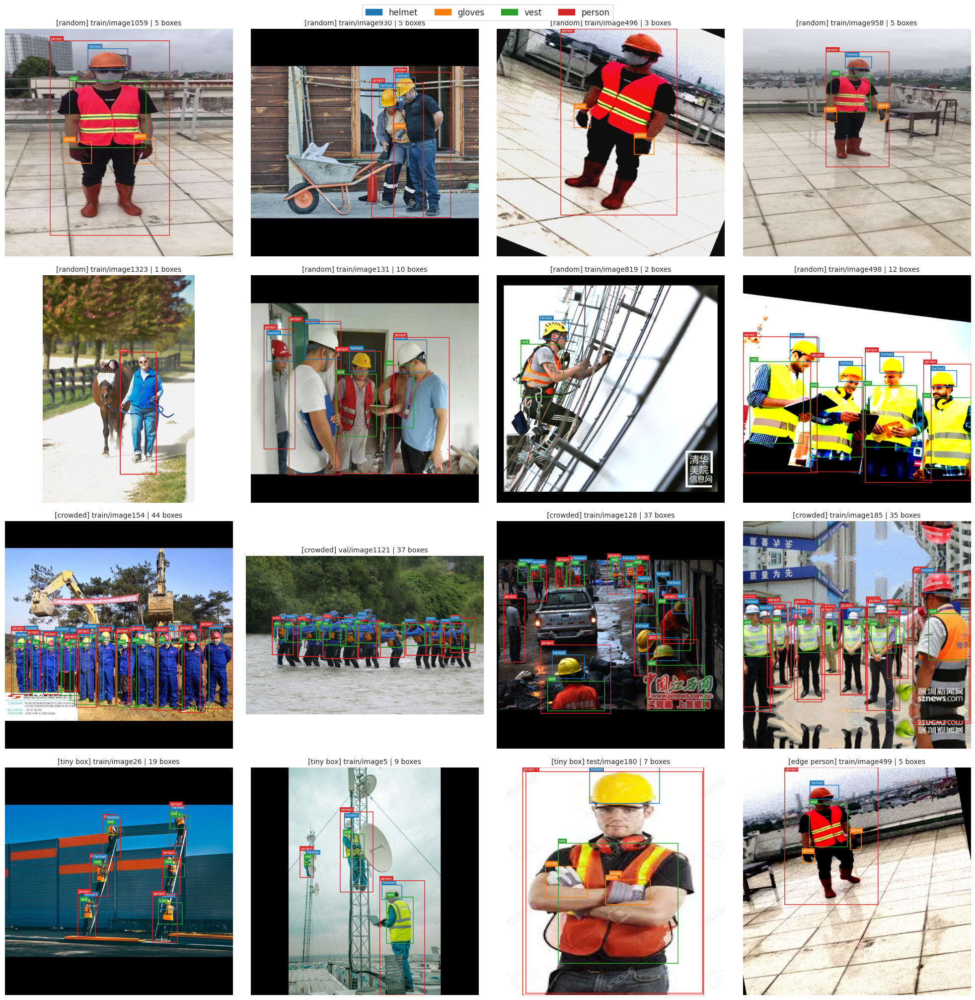

In [14]:
from PIL import ImageDraw, ImageFont

# ===== Colors and font =====
RGB = {i: tuple(int(c * 255) for c in COLORS[n]) for i, n in enumerate(NEW_NAMES)}
def get_font(size):
    try:
        return ImageFont.truetype("DejaVuSans-Bold.ttf", size)
    except Exception:
        return ImageFont.load_default()

# ===== Pick samples =====
rng_seed = 7
groups = [
    ("random", per_img[per_img["split"] == "train"].sample(8, random_state=rng_seed)),
    ("crowded", per_img.sort_values("n_boxes", ascending=False).head(4)),
    ("tiny box", geo[geo["side640"] < 8][["split", "stem"]].drop_duplicates()),
    ("edge person", geo[(geo["class_name"] == "person") & geo["touch_edge"]]
                    [["split", "stem"]].drop_duplicates().sample(1, random_state=rng_seed)),
]
draw_tasks = []
for tag, df in groups:
    for _, r in df.iterrows():
        draw_tasks.append((len(draw_tasks), tag, r["split"], r["stem"]))


def draw_sample(idx, tag, s, stem):
    img_path = os.path.join(OUT, "images", s, file_index[s]["imgs"][stem])
    lbl_path = os.path.join(OUT, "labels", s, stem + ".txt")
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    lw = max(2, int(max(W, H) / 250))
    font = get_font(max(12, int(max(W, H) / 45)))
    draw = ImageDraw.Draw(im)

    n = 0
    with open(lbl_path) as f:
        for line in f:
            p = line.split()
            if len(p) != 5:
                continue
            c = int(p[0]); xc, yc, w, h = map(float, p[1:])
            x1, y1 = (xc - w / 2) * W, (yc - h / 2) * H
            x2, y2 = (xc + w / 2) * W, (yc + h / 2) * H
            draw.rectangle([x1, y1, x2, y2], outline=RGB[c], width=lw)
            label = NEW_NAMES[c]
            tb = draw.textbbox((x1, y1), label, font=font)
            ty = max(0, y1 - (tb[3] - tb[1]) - 4)
            draw.rectangle([x1, ty, x1 + (tb[2] - tb[0]) + 6, ty + (tb[3] - tb[1]) + 4],
                           fill=RGB[c])
            draw.text((x1 + 3, ty), label, fill="white", font=font)
            n += 1
    im.thumbnail((640, 640))
    return idx, tag, s, stem, n, im


# ===== Draw in parallel =====
results = {}
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
    futures = [ex.submit(draw_sample, *t) for t in draw_tasks]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Drawing samples"):
        idx, tag, s, stem, n, im = f.result()
        results[idx] = (tag, s, stem, n, im)

# ===== Plot grid =====
COLS = 4
rows = int(np.ceil(len(results) / COLS))
fig, axes = plt.subplots(rows, COLS, figsize=(COLS * 5, rows * 5))
axes = np.array(axes).reshape(-1)
for ax in axes:
    ax.axis("off")
for i in sorted(results):
    tag, s, stem, n, im = results[i]
    axes[i].imshow(im)
    axes[i].set_title(f"[{tag}] {s}/{stem} | {n} boxes", fontsize=10)

# Legend
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=COLORS[n], label=n) for n in NEW_NAMES],
           loc="upper center", ncol=len(NEW_NAMES), fontsize=12, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout()
plt.show()


In [15]:
!pip install -q -U ultralytics

import os
os.environ["WANDB_MODE"] = "disabled"   # stop the W&B API key prompt
os.environ["WANDB_DISABLED"] = "true"

import torch, ultralytics
from ultralytics import YOLO, settings
from ultralytics.data.utils import check_det_dataset

# ===== Turn off all third-party loggers (persists for DDP subprocesses too) =====
for k in ["wandb", "mlflow", "comet", "clearml", "dvc", "neptune"]:
    try:
        settings.update({k: False})
    except Exception:
        pass

# ===== Versions + hardware =====
ultralytics.checks()
print("\nTorch       :", torch.__version__)
print("CUDA        :", torch.version.cuda, "| available:", torch.cuda.is_available())
print("GPU count   :", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name} | {p.total_memory / 1024**3:.1f} GB")
print("CPU cores   :", os.cpu_count())

# ===== Dataset yaml (hardcoded so it survives a kernel restart) =====
YAML_PATH = "/kaggle/working/ppe_4cls/data.yaml"
assert os.path.exists(YAML_PATH), "data.yaml missing, re-run Cell 6"
info = check_det_dataset(YAML_PATH)
print("\n===== DATASET CHECK =====")
print("nc   :", info["nc"])
print("names:", info["names"])
for s in ["train", "val", "test"]:
    print(f"{s:5s}:", info.get(s))

# ===== Download pretrained weights =====
model = YOLO("yolov8m.pt")
n_params = sum(p.numel() for p in model.model.parameters())
print(f"\nYOLOv8m loaded | {n_params / 1e6:.1f}M params")

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7108.1/8156.9 GB disk)

Torch       : 2.11.0+cu128
CUDA        : 12.8 | available: True
GPU count   : 2
  GPU 0: Tesla T4 | 14.6 GB
  GPU 1: Tesla T4 | 14.6 GB
CPU cores   : 4

===== DATASET CHECK =====
nc   : 4
names: {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'person'}
train: /kaggle/working/ppe_4cls/images/train
val  : /kaggle/working/ppe_4cls/images/val
test : /kaggle/working/ppe_4cls/images/test

YOLOv8m loaded | 25.9M params


In [ ]:
import time, glob

PROJECT = "/kaggle/working/runs"
NAME = "ppe_yolov8m"

model = YOLO("yolov8m.pt")

t0 = time.time()
results = model.train(
    # ----- data -----
    data=YAML_PATH,
    imgsz=640,
    cache="ram",            # dataset is small, removes CPU loading bottleneck

    # ----- schedule -----
    epochs=100,
    patience=20,            # early stop if val mAP stalls for 20 epochs
    optimizer="auto",
    cos_lr=True,
    close_mosaic=10,        # disable mosaic for last 10 epochs

    # ----- hardware -----
    device=[0, 1],          # DDP on both T4s
    batch=32,               # 16 per GPU
    workers=4,
    amp=True,

    # ----- augmentation (dataset is already pre-augmented) -----
    degrees=0.0,
    fliplr=0.5,
    mosaic=1.0,
    translate=0.1,
    scale=0.5,

    # ----- reproducibility + output -----
    seed=42,
    deterministic=True,
    project=PROJECT,
    name=NAME,
    exist_ok=True,
    plots=True,
    verbose=True,
)
elapsed = time.time() - t0
print(f"\nTraining finished in {elapsed / 60:.1f} min")

# ===== Locate best weights (works even if save dir is nested differently) =====
cands = sorted(glob.glob(f"{PROJECT}/**/{NAME}/weights/best.pt", recursive=True),
               key=os.path.getmtime)
BEST = cands[-1] if cands else None
RUN_DIR = os.path.dirname(os.path.dirname(BEST)) if BEST else None
print("Run dir :", RUN_DIR)
print("Best    :", BEST, "| exists:", bool(BEST and os.path.exists(BEST)))

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/ppe_4cls/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosai

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      7.08G      1.721      1.369       1.74         66        640: 100% ━━━━━━━━━━━━ 36/36 2.7it/s 13.3s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.7it/s 1.1s0.7s
                   all        143        747      0.391      0.508      0.286       0.12

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      7.08G      1.732      1.392      1.798         66        640: 100% ━━━━━━━━━━━━ 36/36 2.7it/s 13.4s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.8it/s 1.1s0.7s
                   all        143        747      0.443      0.319      0.291      0.114

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      7.08G       1.72      1.376      1.751         30        640: 100% ━

Run dir: /kaggle/working/runs/ppe_yolov8m
Best   : /kaggle/working/runs/ppe_yolov8m/weights/best.pt


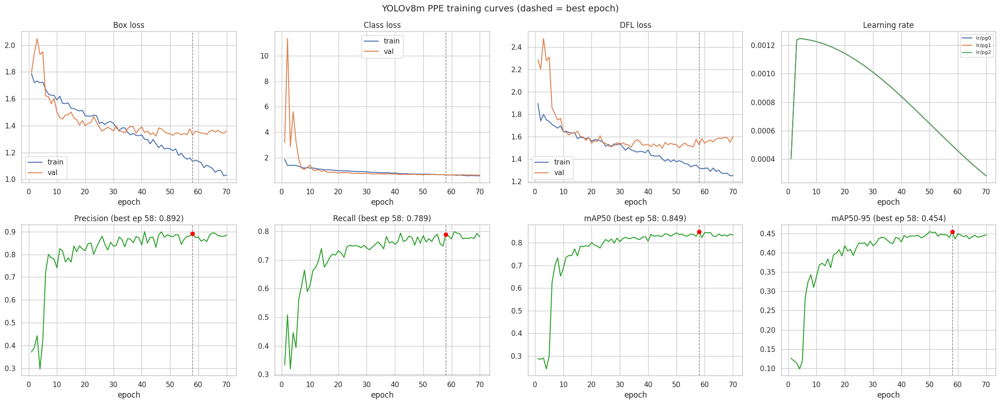

===== RUN SUMMARY =====
Epochs run      : 70  (early stopped)
Best epoch      : 58
Precision      : 0.8922
Recall         : 0.7890
mAP50          : 0.8489
mAP50-95       : 0.4541

Min total val loss at epoch 45 | best mAP epoch 58
Val loss rise after its minimum: 2.5%


In [17]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

# ===== Find the run (current session or attached notebook output) =====
def find_best(name="ppe_yolov8m"):
    for root in ["/kaggle/working/runs", "/kaggle/input"]:
        c = glob.glob(f"{root}/**/{name}/weights/best.pt", recursive=True)
        if c:
            return sorted(c, key=os.path.getmtime)[-1]
    return None

BEST = find_best()
assert BEST, "best.pt not found. Attach the notebook output via Add Input."
RUN_DIR = os.path.dirname(os.path.dirname(BEST))
print("Run dir:", RUN_DIR)
print("Best   :", BEST)

# ===== Load results.csv =====
res = pd.read_csv(os.path.join(RUN_DIR, "results.csv"))
res.columns = [c.strip() for c in res.columns]
res["fitness"] = 0.1 * res["metrics/mAP50(B)"] + 0.9 * res["metrics/mAP50-95(B)"]
best_ep = int(res.loc[res["fitness"].idxmax(), "epoch"])
last_ep = int(res["epoch"].max())

# ===== Plot =====
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
pairs = [("box_loss", "Box loss"), ("cls_loss", "Class loss"), ("dfl_loss", "DFL loss")]
for i, (k, t) in enumerate(pairs):
    ax = axes[0, i]
    ax.plot(res["epoch"], res[f"train/{k}"], label="train")
    ax.plot(res["epoch"], res[f"val/{k}"], label="val")
    ax.axvline(best_ep, ls="--", c="gray", lw=1)
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend()

ax = axes[0, 3]
lr_cols = [c for c in res.columns if c.startswith("lr/")]
for c in lr_cols:
    ax.plot(res["epoch"], res[c], label=c)
ax.set_title("Learning rate"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)

metrics = [("metrics/precision(B)", "Precision"), ("metrics/recall(B)", "Recall"),
           ("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")]
for i, (k, t) in enumerate(metrics):
    ax = axes[1, i]
    ax.plot(res["epoch"], res[k], c="tab:green")
    ax.axvline(best_ep, ls="--", c="gray", lw=1)
    ax.scatter(best_ep, res.loc[res["epoch"] == best_ep, k], c="red", zorder=5)
    ax.set_title(f"{t} (best ep {best_ep}: {res.loc[res['epoch'] == best_ep, k].item():.3f})")
    ax.set_xlabel("epoch")

plt.suptitle("YOLOv8m PPE training curves (dashed = best epoch)", fontsize=14)
plt.tight_layout()
plt.show()

# ===== Text summary =====
print("===== RUN SUMMARY =====")
print(f"Epochs run      : {last_ep}  {'(early stopped)' if last_ep < 100 else '(full run)'}")
print(f"Best epoch      : {best_ep}")
row = res.loc[res["epoch"] == best_ep].iloc[0]
for k, t in metrics:
    print(f"{t:15s}: {row[k]:.4f}")

# Overfitting check: where did val loss bottom out vs best mAP epoch?
val_loss = res["val/box_loss"] + res["val/cls_loss"] + res["val/dfl_loss"]
min_vl_ep = int(res.loc[val_loss.idxmin(), "epoch"])
print(f"\nMin total val loss at epoch {min_vl_ep} | best mAP epoch {best_ep}")
print(f"Val loss rise after its minimum: {(val_loss.iloc[-1] / val_loss.min() - 1) * 100:.1f}%")


========== VAL ==========
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,842,076 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2123.1±1071.7 MB/s, size: 100.8 KB)
val: Scanning /kaggle/working/ppe_4cls/labels/val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 37.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.1it/s 4.2s0.4ss
                   all        143        747      0.881      0.784      0.844      0.456
Speed: 2.5ms preprocess, 19.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/runs/eval_val

========== TEST ==========
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,842,076 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 

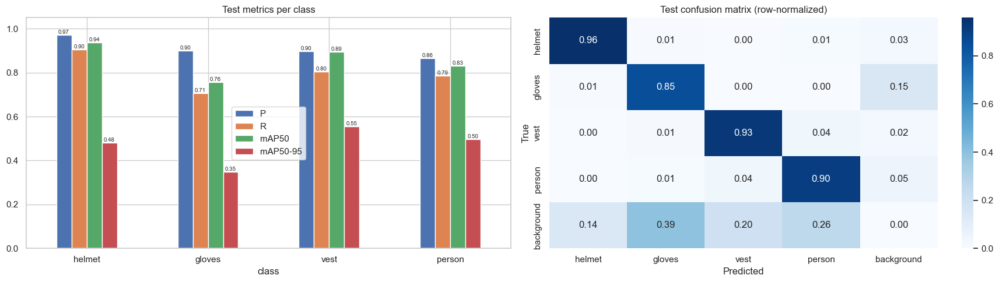

===== CONFUSION MATRIX (test, raw counts, rows = true) =====
            helmet  gloves  vest  person  background
helmet         184       1     0       2           5
gloves           1     138     0       0          24
vest             0       2   165       7           4
person           0       2     9     213          12
background     557    1559   794    1047           0

 BoxF1_curve.png


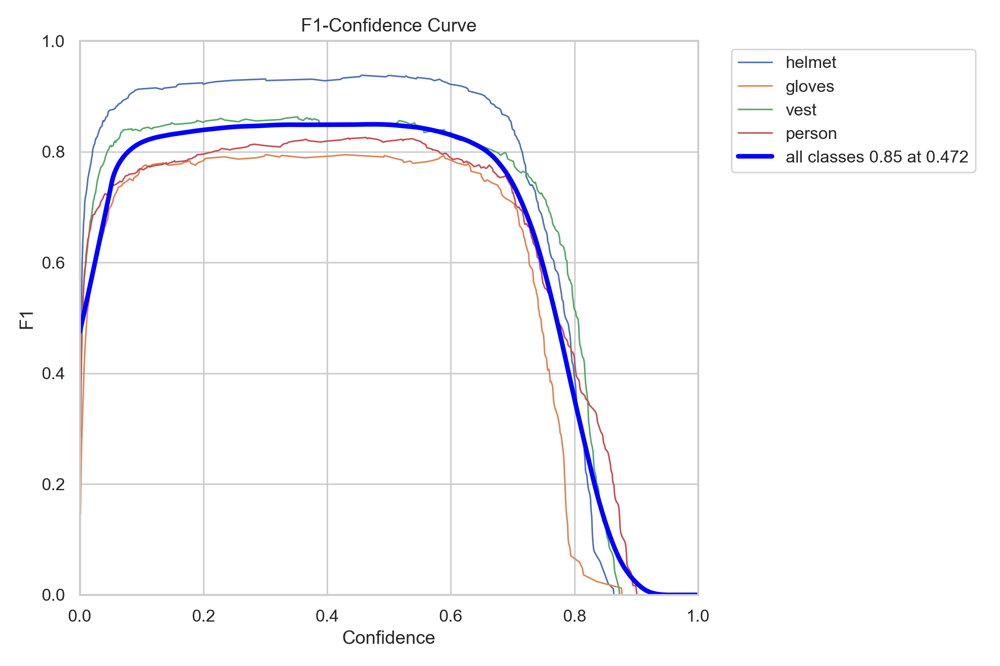


 BoxPR_curve.png


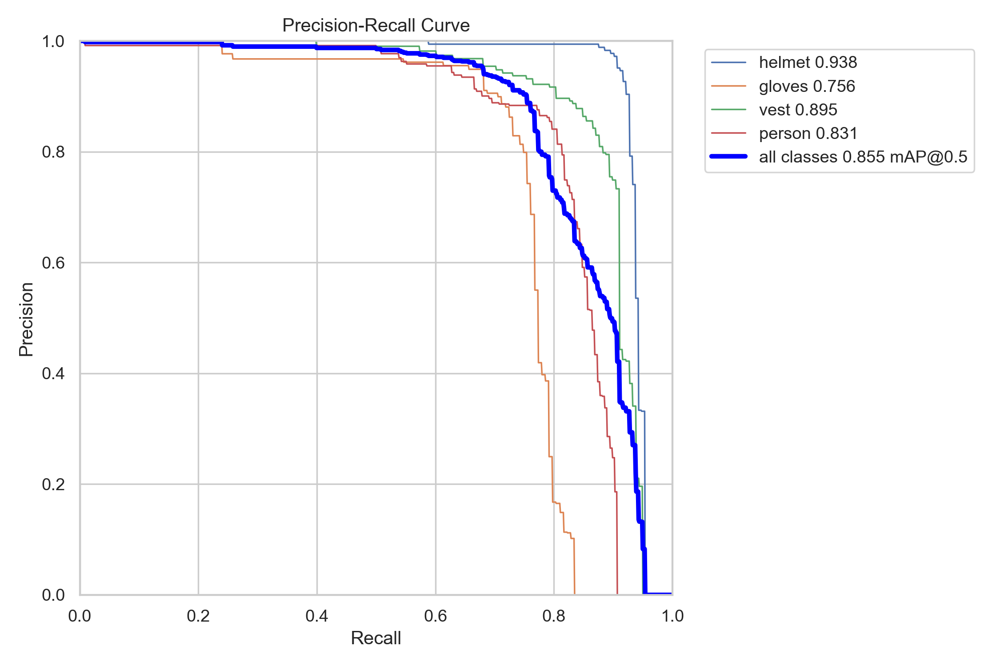

In [18]:
import numpy as np
import seaborn as sns
from IPython.display import Image as IPImage, display

EVAL_PROJECT = "/kaggle/working/runs"
best_model = YOLO(BEST)
names = best_model.names   # {0:'helmet', 1:'gloves', 2:'vest', 3:'person'}

# ===== Evaluate on val and test =====
evals = {}
for split in ["val", "test"]:
    print(f"\n========== {split.upper()} ==========")
    evals[split] = best_model.val(
        data=YAML_PATH, split=split, imgsz=640, batch=16, device=0,
        conf=0.001, iou=0.7, plots=True,
        project=EVAL_PROJECT, name=f"eval_{split}", exist_ok=True, verbose=False,
    )

# ===== Per-class comparison table =====
rows = []
for split, m in evals.items():
    b = m.box
    rows.append({"split": split, "class": "ALL", "P": b.mp, "R": b.mr,
                 "mAP50": b.map50, "mAP50-95": b.map})
    for i, c in enumerate(b.ap_class_index):
        rows.append({"split": split, "class": names[int(c)], "P": b.p[i], "R": b.r[i],
                     "mAP50": b.ap50[i], "mAP50-95": b.ap[i]})
cmp_df = pd.DataFrame(rows)
wide = cmp_df.pivot(index="class", columns="split", values=["P", "R", "mAP50", "mAP50-95"])
wide = wide.reindex(["ALL"] + list(names.values()))
for metric in ["mAP50", "mAP50-95"]:
    wide[(metric, "gap")] = wide[(metric, "test")] - wide[(metric, "val")]
print("\n===== VAL vs TEST (per class) =====")
print(wide.round(3).to_string())

# ===== Per-class bar chart (test) =====
t = cmp_df[(cmp_df["split"] == "test") & (cmp_df["class"] != "ALL")].set_index("class")
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
t[["P", "R", "mAP50", "mAP50-95"]].plot(kind="bar", ax=axes[0], rot=0)
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt="%.2f", fontsize=7)
axes[0].set_ylim(0, 1.05); axes[0].set_title("Test metrics per class")

# ===== Confusion matrix (test): rows = true, cols = predicted =====
cm = evals["test"].confusion_matrix.matrix.T          # ultralytics stores [pred, true]
labels = list(names.values()) + ["background"]
cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=axes[1],
            xticklabels=labels, yticklabels=labels)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
axes[1].set_title("Test confusion matrix (row-normalized)")
plt.tight_layout()
plt.show()

print("===== CONFUSION MATRIX (test, raw counts, rows = true) =====")
print(pd.DataFrame(cm.astype(int), index=labels, columns=labels))

# ===== Ultralytics curves for test =====
test_dir = evals["test"].save_dir
for pat in ["*F1*curve*.png", "*PR*curve*.png"]:
    for p in sorted(glob.glob(os.path.join(test_dir, pat))):
        print("\n", os.path.basename(p))
        display(IPImage(filename=p, width=700))

Best conf (max mean F1 on test): 0.455 | F1 = 0.851


Predicting:   0%|          | 0/141 [00:00<?, ?it/s]


===== TEST @ conf=0.455, IoU=0.5 =====
         TP  FP  FN      P      R     F1
class                                   
helmet  173   6  19  0.966  0.901  0.933
gloves  115  13  48  0.898  0.706  0.790
vest    147  17  31  0.896  0.826  0.860
person  188  29  48  0.866  0.797  0.830

Images with zero errors: 73 / 141


Drawing:   0%|          | 0/8 [00:00<?, ?it/s]

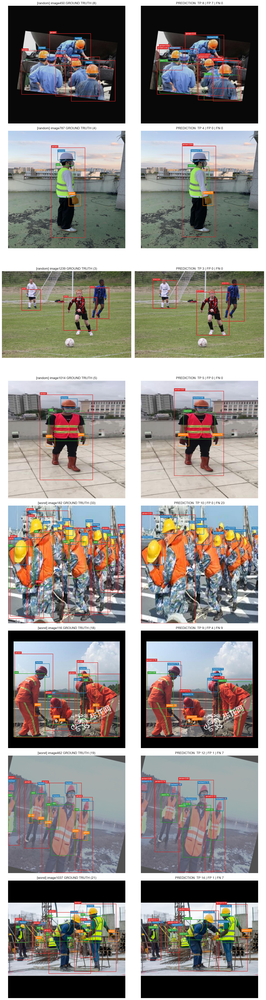

In [19]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

DS = "/kaggle/working/ppe_4cls"
names = best_model.names
NC = len(names)
PAL = [(31, 119, 180), (255, 127, 14), (44, 160, 44), (214, 39, 40)]
IOU_THR = 0.5

# ===== 1. Best confidence threshold from test F1 curve =====
bx = evals["test"].box
try:
    f1_mean = bx.f1_curve.mean(0)
    CONF = float(bx.px[f1_mean.argmax()])
    print(f"Best conf (max mean F1 on test): {CONF:.3f} | F1 = {f1_mean.max():.3f}")
except Exception as e:
    CONF = 0.25
    print("F1 curve unavailable, using default conf 0.25 |", e)

# ===== 2. Predict on all test images (batched GPU) =====
test_imgs = sorted(glob.glob(f"{DS}/images/test/*"))
preds = {}
stream = best_model.predict(test_imgs, imgsz=640, conf=CONF, iou=0.7, device=0,
                            batch=16, stream=True, verbose=False)
for r in tqdm(stream, total=len(test_imgs), desc="Predicting"):
    b = r.boxes
    preds[Path(r.path).stem] = (b.xyxyn.cpu().numpy(), b.cls.cpu().numpy().astype(int),
                                b.conf.cpu().numpy())

# ===== 3. Load ground truth (xyxy normalized) =====
def load_gt(stem):
    arr = np.loadtxt(f"{DS}/labels/test/{stem}.txt", ndmin=2)
    if arr.size == 0:
        return np.zeros((0, 4)), np.zeros(0, int)
    c, xc, yc, w, h = arr.T
    return np.stack([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2], 1), c.astype(int)

def iou_one(box, boxes):
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    a = (box[2] - box[0]) * (box[3] - box[1])
    b = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (a + b - inter + 1e-9)

# ===== 4. Match predictions to GT, per image and per class =====
per_class = {c: Counter() for c in range(NC)}
img_stats = []
for p in test_imgs:
    stem = Path(p).stem
    gb, gc = load_gt(stem)
    pb, pc, pconf = preds.get(stem, (np.zeros((0, 4)), np.zeros(0, int), np.zeros(0)))
    used, tp, fp = set(), 0, 0
    for i in np.argsort(-pconf):
        cand = [j for j in range(len(gb)) if gc[j] == pc[i] and j not in used]
        if cand:
            ious = iou_one(pb[i], gb[cand])
            k = int(ious.argmax())
            if ious[k] >= IOU_THR:
                used.add(cand[k]); tp += 1; per_class[pc[i]]["TP"] += 1
                continue
        fp += 1; per_class[pc[i]]["FP"] += 1
    for j in range(len(gb)):
        if j not in used:
            per_class[gc[j]]["FN"] += 1
    img_stats.append({"stem": stem, "path": p, "gt": len(gb), "tp": tp,
                      "fp": fp, "fn": len(gb) - len(used)})
img_stats = pd.DataFrame(img_stats)
img_stats["errors"] = img_stats["fp"] + img_stats["fn"]

# ===== 5. Per-class P/R/F1 at the deployment threshold =====
pc_rows = []
for c in range(NC):
    tp, fp, fn = per_class[c]["TP"], per_class[c]["FP"], per_class[c]["FN"]
    P = tp / max(tp + fp, 1); R = tp / max(tp + fn, 1)
    pc_rows.append({"class": names[c], "TP": tp, "FP": fp, "FN": fn,
                    "P": P, "R": R, "F1": 2 * P * R / max(P + R, 1e-9)})
pc_df = pd.DataFrame(pc_rows).set_index("class")
print(f"\n===== TEST @ conf={CONF:.3f}, IoU={IOU_THR} =====")
print(pc_df.round(3).to_string())
print(f"\nImages with zero errors: {(img_stats['errors'] == 0).sum()} / {len(img_stats)}")

# ===== 6. Draw GT vs prediction (parallel) =====
def font(sz):
    try:
        return ImageFont.truetype("DejaVuSans-Bold.ttf", sz)
    except Exception:
        return ImageFont.load_default()

def draw(path, boxes, cls, conf=None):
    im = Image.open(path).convert("RGB"); W, H = im.size
    d = ImageDraw.Draw(im); lw = max(2, int(max(W, H) / 250)); f = font(max(12, int(max(W, H) / 45)))
    for i, (b, c) in enumerate(zip(boxes, cls)):
        x1, y1, x2, y2 = b[0] * W, b[1] * H, b[2] * W, b[3] * H
        d.rectangle([x1, y1, x2, y2], outline=PAL[c], width=lw)
        txt = names[c] if conf is None else f"{names[c]} {conf[i]:.2f}"
        tb = d.textbbox((x1, y1), txt, font=f); th = tb[3] - tb[1]
        ty = max(0, y1 - th - 4)
        d.rectangle([x1, ty, x1 + tb[2] - tb[0] + 6, ty + th + 4], fill=PAL[c])
        d.text((x1 + 3, ty), txt, fill="white", font=f)
    im.thumbnail((640, 640))
    return im

def make_pair(idx, tag, row):
    gb, gc = load_gt(row["stem"])
    pb, pc, pconf = preds[row["stem"]]
    return idx, tag, row, draw(row["path"], gb, gc), draw(row["path"], pb, pc, pconf)

picks = ([("random", r) for _, r in img_stats.sample(4, random_state=1).iterrows()] +
         [("worst", r) for _, r in img_stats.sort_values("errors", ascending=False).head(4).iterrows()])

pairs = {}
with ThreadPoolExecutor(max_workers=8) as ex:
    futs = [ex.submit(make_pair, i, t, r) for i, (t, r) in enumerate(picks)]
    for fu in tqdm(as_completed(futs), total=len(futs), desc="Drawing"):
        i, t, r, g, p = fu.result()
        pairs[i] = (t, r, g, p)

fig, axes = plt.subplots(len(pairs), 2, figsize=(14, 6.5 * len(pairs)))
for i in sorted(pairs):
    t, r, g, p = pairs[i]
    axes[i, 0].imshow(g); axes[i, 0].set_title(f"[{t}] {r['stem']} GROUND TRUTH ({r['gt']})")
    axes[i, 1].imshow(p)
    axes[i, 1].set_title(f"PREDICTION  TP {r['tp']} | FP {r['fp']} | FN {r['fn']}")
    axes[i, 0].axis("off"); axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

In [20]:
import shutil, json, zipfile

EXPORT_DIR = "/kaggle/working/export"
os.makedirs(EXPORT_DIR, exist_ok=True)

# ===== 1. Copy best.pt (export from the copy, since /kaggle/input is read-only) =====
pt_dst = os.path.join(EXPORT_DIR, "ppe_yolov8m_best.pt")
shutil.copy2(BEST, pt_dst)
print("Saved:", pt_dst)

# ===== 2. Export ONNX =====
onnx_path = YOLO(pt_dst).export(format="onnx", imgsz=640, simplify=True, dynamic=False)
print("Exported:", onnx_path)

# ===== 3. Verify ONNX gives the same accuracy as .pt on test =====
onnx_eval = YOLO(onnx_path, task="detect").val(
    data=YAML_PATH, split="test", imgsz=640, batch=1, device=0,
    conf=0.001, iou=0.7, plots=False,
    project="/kaggle/working/runs", name="eval_test_onnx", exist_ok=True, verbose=False,
)
pt_b, ox_b = evals["test"].box, onnx_eval.box
print("\n===== .pt vs ONNX (test) =====")
print(f"mAP50    : pt {pt_b.map50:.4f} | onnx {ox_b.map50:.4f} | diff {ox_b.map50 - pt_b.map50:+.4f}")
print(f"mAP50-95 : pt {pt_b.map:.4f} | onnx {ox_b.map:.4f} | diff {ox_b.map - pt_b.map:+.4f}")

# ===== 4. Metadata json =====
meta = {
    "model": "YOLOv8m",
    "classes": {int(k): v for k, v in names.items()},
    "imgsz": 640,
    "conf_threshold": round(CONF, 3),
    "iou_nms": 0.7,
    "metrics": {
        split: {"P": round(float(m.box.mp), 4), "R": round(float(m.box.mr), 4),
                "mAP50": round(float(m.box.map50), 4), "mAP50-95": round(float(m.box.map), 4)}
        for split, m in evals.items()
    },
    "test_per_class_at_conf": pc_df.round(4).reset_index().to_dict(orient="records"),
}
with open(os.path.join(EXPORT_DIR, "model_info.json"), "w") as f:
    json.dump(meta, f, indent=2)

# ===== 5. Copy training artifacts =====
for fname in ["results.csv", "args.yaml", "results.png"]:
    src = os.path.join(RUN_DIR, fname)
    if os.path.exists(src):
        shutil.copy2(src, EXPORT_DIR)
for p in glob.glob(os.path.join(evals["test"].save_dir, "*.png")):
    shutil.copy2(p, os.path.join(EXPORT_DIR, "test_" + os.path.basename(p)))
shutil.copy2(YAML_PATH, EXPORT_DIR)

# ===== 6. Zip everything for download =====
ZIP_PATH = "/kaggle/working/ppe_yolov8m_export.zip"
files = [os.path.join(EXPORT_DIR, f) for f in sorted(os.listdir(EXPORT_DIR))]
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for fp in tqdm(files, desc="Zipping"):
        z.write(fp, arcname=os.path.basename(fp))

print("\n===== EXPORT CONTENTS =====")
for fp in files:
    print(f"{os.path.basename(fp):40s} {os.path.getsize(fp) / 1024**2:7.2f} MB")
print(f"\nZip: {ZIP_PATH} ({os.path.getsize(ZIP_PATH) / 1024**2:.1f} MB)")

Saved: /kaggle/working/export/ppe_yolov8m_best.pt
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 92 layers, 25,842,076 parameters, 0 gradients, 78.7 GFLOPs

PyTorch: starting from '/kaggle/working/export/ppe_yolov8m_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (49.6 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 375ms
Prepared 2 packages in 2.38s
Installed 2 packages in 13ms
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 3.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxsl

Zipping:   0%|          | 0/13 [00:00<?, ?it/s]


===== EXPORT CONTENTS =====
args.yaml                                   0.00 MB
data.yaml                                   0.00 MB
model_info.json                             0.00 MB
ppe_yolov8m_best.onnx                      98.83 MB
ppe_yolov8m_best.pt                        49.63 MB
results.csv                                 0.01 MB
results.png                                 0.25 MB
test_BoxF1_curve.png                        0.19 MB
test_BoxPR_curve.png                        0.14 MB
test_BoxP_curve.png                         0.15 MB
test_BoxR_curve.png                         0.18 MB
test_confusion_matrix.png                   0.14 MB
test_confusion_matrix_normalized.png        0.15 MB

Zip: /kaggle/working/ppe_yolov8m_export.zip (128.9 MB)


In [21]:
import os
from IPython.display import FileLink

os.chdir("/kaggle/working")          # FileLink needs a path relative to the working dir
FileLink("ppe_yolov8m_export.zip")

/kaggle/working/ppe_yolov8m_export.zip